In [1]:
import numpy as np
import mrcfile
from pathlib import Path
from matplotlib import pyplot as plt   
import torch

import einops

In [2]:
tomogram_base = Path("/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1and5F11_tomograms/TOP_TOMOS/20241018_HippWaffleDual_166/best_alignment/")
tomo_name = "20241018_HippWaffleDual_166"

In [3]:
with mrcfile.open(list(tomogram_base.glob(f"*_flat.mrc"))[0]) as mrc:
    tomogram_data = torch.tensor(mrc.data.copy())

In [4]:
from findingampa.utils.analysis import get_active_zone_points
# Get only every 10th point to speed things up
pres_poins = np.loadtxt(tomogram_base / "aunps" / f"presynatpticmembranes_1.txt")[::10]
post_poins = np.loadtxt(tomogram_base / "aunps" / f"postsynapticmembranes_1.txt")[::10]

pre_points_in_active_zone, post_poins_in_active_zone = get_active_zone_points(pres_poins, post_poins, 40)



In [5]:
from findingampa.utils.analysis import create_coordinate_system_from_points

cs, center = create_coordinate_system_from_points(pre_points_in_active_zone, post_poins_in_active_zone)

center

array([332.78526261, 410.93045759, 167.34684105])

In [34]:
all_poins_transformed = (torch.tensor(all_poins) - torch.tensor(center)) @ torch.tensor(cs.T)
w, h, d = (torch.max(-torch.min(all_poins_transformed, dim=0).values, torch.max(all_poins_transformed, dim=0).values).floor() + 1).int()
w

tensor(117, dtype=torch.int32)

In [35]:
x = torch.linspace(-w, w, 2*w+1, dtype=torch.float64)
y = torch.linspace(-h, h, 2*h+1, dtype=torch.float64)
z = torch.linspace(-d, d, 2*d+1, dtype=torch.float64)
mg = torch.cartesian_prod(x, y, z)
#print(mg)
# Construct 100x 100 mesh around pre points center in fractional coordinates using v2 and v3
grid = mg @ torch.tensor([cs]) + torch.tensor(center)


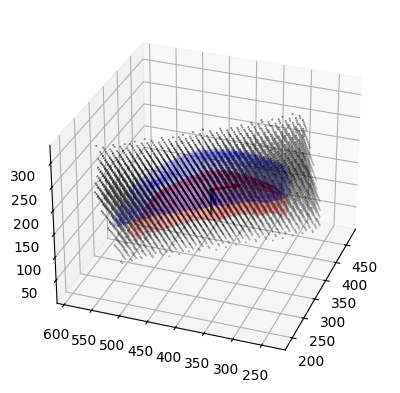

In [101]:
plt.figure()
ax = plt.subplot(111, projection='3d')
# rotate plot
ax.view_init(elev=30, azim=200)
ax.scatter(post_poins_in_active_zone[:,0], post_poins_in_active_zone[:,1], post_poins_in_active_zone[:,2], c='r',s=0.1,alpha=0.1)
ax.scatter(pre_points_in_active_zone[:,0], pre_points_in_active_zone[:,1], pre_points_in_active_zone[:,2], c='b', s=0.1,alpha=0.1)

ax.scatter(center[0], center[1], center[2], c='g', s=10)
ax.quiver(center[0], center[1], center[2], cs[2][0]*50, cs[2][1]*50, cs[2][2]*50, color='g')
ax.quiver(center[0], center[1], center[2], cs[0][0]*50, cs[0][1]*50, cs[0][2]*50, color='b')
ax.quiver(center[0], center[1], center[2], cs[1][0]*50, cs[1][1]*50, cs[1][2]*50, color='r')
ax.scatter(grid.reshape(-1,3)[::1000,0], grid.reshape(-1,3)[::1000,1], grid.reshape(-1,3)[::1000,2], c='k', s=0.1)

In [36]:
# Convert grid to coordinates within {-1 and 1} as required by pytorch
torch.tensor(tomogram_data.shape).flip(dims=(0,)).double()

grid_sc = grid / (torch.tensor(tomogram_data.shape).flip(dims=(0,)).double() / 2.0 ) - 1.0

grid_sc.shape

grid_sc = grid_sc.reshape(1,2*w+1,2*h+1,2*d+1,3).float()
tomogram_data_sc = tomogram_data.reshape(1,1, *tomogram_data.shape)

In [37]:
res = torch.nn.functional.grid_sample(tomogram_data_sc, grid_sc)

/home/gouauxlab/andecath/env/lib/python3.11/site-packages/torch/nn/functional.py:4902: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  warnings.warn(


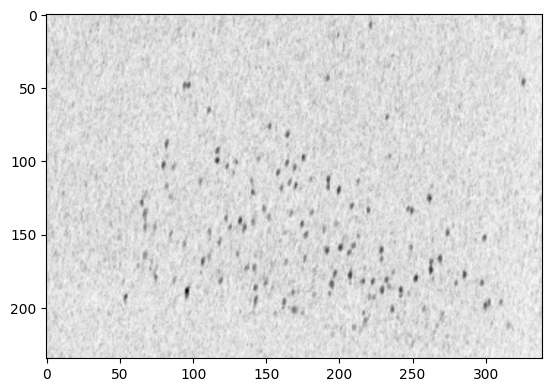

In [38]:
plt.imshow(torch.min(res[0,0],axis=2).values,cmap='gray',interpolation='mitchell')

In [39]:
with mrcfile.open(list(tomogram_base.glob(f"*_ddw.mrc"))[0]) as mrc:
    tomogram_data_ddw = torch.tensor(mrc.data.copy())
with mrcfile.open(list(tomogram_base.glob(f"*_denoised.mrc"))[0]) as mrc:
    tomogram_data_den = torch.tensor(mrc.data.copy())

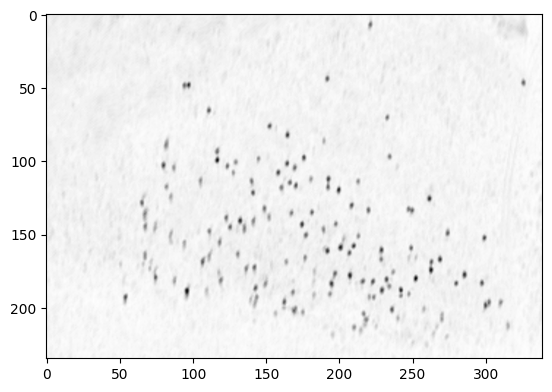

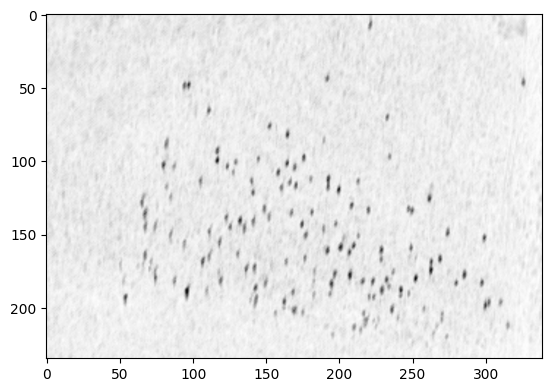

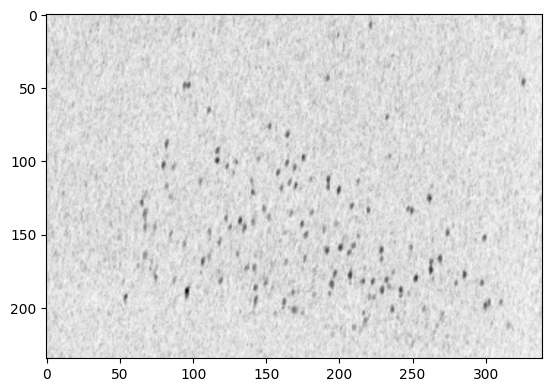

In [40]:
tomogram_data_ddw_sc = tomogram_data_ddw.reshape(1,1, *tomogram_data.shape)
res_ddw = torch.nn.functional.grid_sample(tomogram_data_ddw_sc, grid_sc)
tomogram_data_den_sc = tomogram_data_den.reshape(1,1, *tomogram_data.shape)
res_den = torch.nn.functional.grid_sample(tomogram_data_den_sc, grid_sc)
plt.imshow(torch.min(res_ddw[0,0],axis=2).values,cmap='gray',interpolation='mitchell')
plt.show()
plt.imshow(torch.min(res_den[0,0],axis=2).values,cmap='gray',interpolation='mitchell')
plt.show()
plt.imshow(torch.min(res[0,0],axis=2).values,cmap='gray',interpolation='mitchell')

In [51]:
from scipy.spatial import cKDTree
import starfile
aunp_star = tomogram_base / "aunps" /  "aunp_tm.star"


aunp_data = starfile.read(aunp_star)

pre_kd = cKDTree(pres_poins)
post_kd = cKDTree(post_poins)

aunp_pos = aunp_data[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values
aunp_data["Size"] = aunp_data["faTomo_gaussianFitSigmaX"] * aunp_data["faTomo_gaussianFitSigmaY"] * aunp_data["faTomo_gaussianFitSigmaZ"]
pre_dists, pre_idxs = pre_kd.query(aunp_pos)
post_dists, post_idxs = post_kd.query(aunp_pos)
aunp_data["pre_dist"] = pre_dists
aunp_data["post_dist"] = post_dists



In [52]:
aunp_data

,faTM_PeakX,faTM_PeakY,faTM_PeakZ,faTM_PeakScore,faTM_gaussianFitX,faTM_gaussianFitY,faTM_gaussianFitZ,faTM_gaussianFitSigmaX,faTM_gaussianFitSigmaY,faTM_gaussianFitSigmaZ,...,faTomo_gaussianFitX,faTomo_gaussianFitY,faTomo_gaussianFitZ,faTomo_gaussianFitSigmaX,faTomo_gaussianFitSigmaY,faTomo_gaussianFitSigmaZ,faTomo_gaussianFitAmplitude,Size,pre_dist,post_dist
0,364.0,383.0,134.0,0.648445,-0.346377,0.047083,0.620517,0.714919,1.227538,2.622054,...,-0.787223,-0.452270,0.463930,0.808930,1.296233,2.995339,-7.081143,3.140798,11.172440,14.537330
1,389.0,325.0,128.0,0.636223,0.008256,0.071266,-0.172499,0.803356,0.890689,2.620132,...,-0.618018,-0.556622,-0.040835,0.909123,0.957719,3.702198,-7.311446,3.223446,9.794391,18.799507
2,338.0,480.0,91.0,0.624688,-0.283751,0.087303,0.453472,0.767281,0.966004,3.082969,...,-0.715751,-0.506047,0.150972,0.818939,1.054961,4.404608,-8.112912,3.805355,6.878424,25.014749
3,401.0,286.0,107.0,0.621943,0.148550,-0.075693,0.010972,0.722035,0.883407,2.979782,...,-0.393801,-0.772485,-0.193314,0.741106,0.988590,3.324547,-6.794966,2.435729,27.283029,20.482943
4,349.0,408.0,146.0,0.615347,0.075128,-0.041033,-0.028867,0.744565,0.845880,2.820811,...,-0.550194,-0.693014,-0.722929,0.722328,1.016490,2.817127,-6.754032,2.068445,10.927381,16.326614
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13072,267.0,387.0,336.0,0.300013,-0.077101,-0.784789,0.316583,0.734614,1.050574,2.101524,...,-0.546393,-1.423262,-0.508711,0.526263,1.172971,1.921461,-3.989160,1.186101,56.525345,97.136128
13073,431.0,52.0,155.0,0.300007,0.714317,0.316622,-0.268169,0.820090,1.178213,2.813432,...,0.294642,-0.199506,-0.862446,0.872479,0.997748,2.655411,-2.535460,2.311573,225.448799,208.779473
13074,389.0,688.0,148.0,0.300006,0.078896,0.520114,-0.433730,0.707125,1.222706,2.535622,...,-0.464298,0.128843,-0.977465,0.437562,1.347858,2.153392,-4.008836,1.270009,23.284657,212.253074
13075,218.0,688.0,335.0,0.300004,0.384032,-0.241354,0.640573,0.473472,0.745614,2.101653,...,0.034709,-1.150020,-0.578684,0.564547,1.200468,1.851016,-2.509459,1.254472,84.391767,256.196966


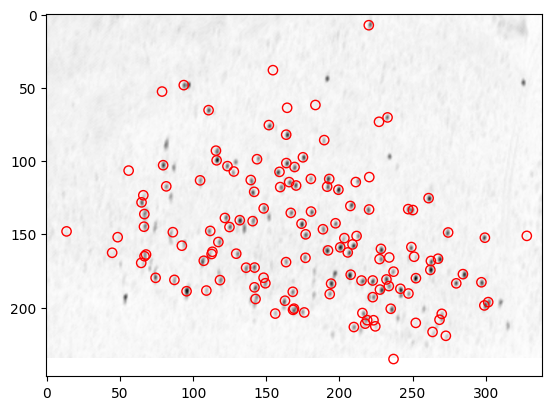

In [102]:
in_cleft_aunps = aunp_data[(aunp_data["pre_dist"] < 45) & (aunp_data["post_dist"] < 45)]

slected_aunps = in_cleft_aunps[in_cleft_aunps["faTM_PeakScore"] > 0.35]
slected_aunps = slected_aunps[slected_aunps["faTomo_gaussianFitAmplitude"] < -2]
selected_aunp_pos = slected_aunps[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values - slected_aunps[["faTomo_gaussianFitZ", "faTomo_gaussianFitY", "faTomo_gaussianFitX"]].values
selected_aunp_pos_transformed = (torch.tensor(selected_aunp_pos) - torch.tensor(center)) @ torch.tensor(cs.T)
plt.imshow(torch.min(res_ddw[0,0],axis=2).values,cmap='gray',interpolation='mitchell')
plt.scatter(selected_aunp_pos_transformed[:,1]+h, selected_aunp_pos_transformed[:,0]+w, s=45,facecolors='none', edgecolors='r')
plt.show()

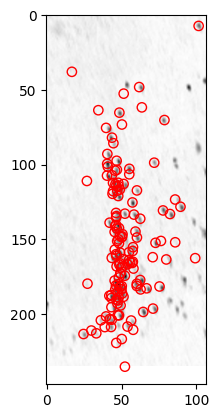

In [105]:
plt.imshow(torch.min(res_ddw[0,0],axis=1).values,cmap='gray',interpolation='mitchell')
plt.scatter(selected_aunp_pos_transformed[:,2]+d, selected_aunp_pos_transformed[:,0]+w, s=45,facecolors='none', edgecolors='r')
plt.show()

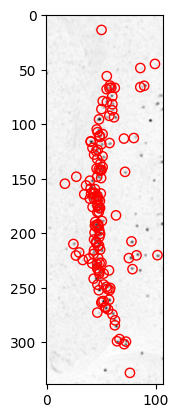

In [106]:
plt.imshow(torch.min(res_ddw[0,0],axis=0).values,cmap='gray',interpolation='mitchell')
plt.scatter(selected_aunp_pos_transformed[:,2]+d, selected_aunp_pos_transformed[:,1]+h, s=45,facecolors='none', edgecolors='r')
plt.show()